#  K-means


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
DATA_PATH = Path('Mall_Customers.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('lab4') / 'Mall_Customers.csv'
df = pd.read_csv(DATA_PATH)
print(f'size: {df.shape[0]} мөр × {df.shape[1]} багана')
df.head()

Хэмжээ: 200 мөр × 5 багана


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. EDA — өгөгдлийн чанар ба статистик

In [12]:
print('Өгөгдлийн төрөл ба non-null тоо:')
df.info()
print('\nАлдагдсан утгын тоо:')
display(df.isna().sum().rename('missing_count').to_frame())
print(f'Давхардсан мөр: {df.duplicated().sum()}')

Өгөгдлийн төрөл ба non-null тоо:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Алдагдсан утгын тоо:


,missing_count
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


Давхардсан мөр: 0


In [13]:
numeric_cols = df.select_dtypes(include='number').columns
eda_stats = df[numeric_cols].describe().T
eda_stats['median'] = df[numeric_cols].median()
eda_stats = eda_stats[['mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']]
display(eda_stats.round(2))

,mean,median,std,min,25%,50%,75%,max
CustomerID,100.50,100.5,57.88,1.0,50.75,100.5,150.25,200.0
Age,38.85,36.0,13.97,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),60.56,61.5,26.26,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),50.20,50.0,25.82,1.0,34.75,50.0,73.00,99.0


In [14]:
gender_counts = df['Gender'].value_counts().rename_axis('Gender').to_frame('count')
gender_counts['ratio'] = (gender_counts['count'] / len(df)).map(lambda x: f'{x:.1%}')
display(gender_counts)

,count,ratio
Gender,,
Female,112,56.0%
Male,88,44.0%


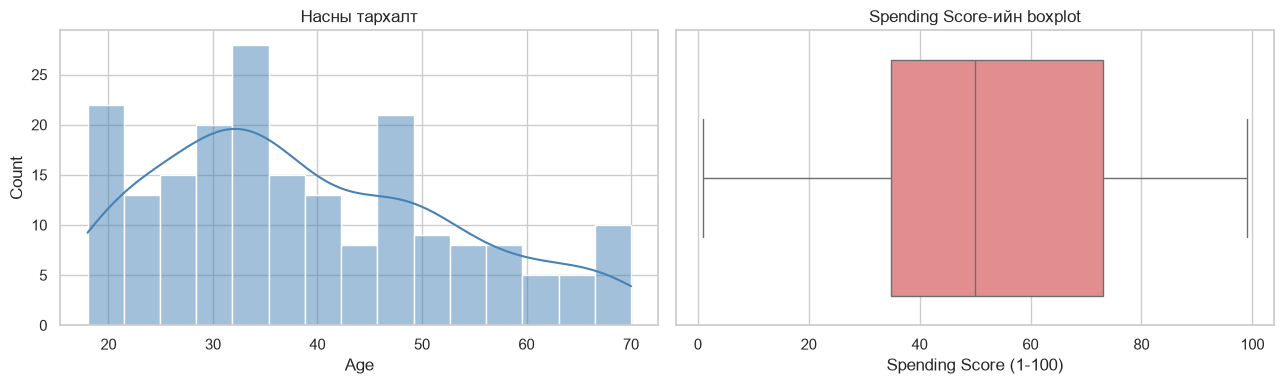

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x='Age', bins=15, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Насны тархалт')
sns.boxplot(data=df, x='Spending Score (1-100)', ax=axes[1], color='lightcoral')
axes[1].set_title('Spending Score-ийн boxplot')
plt.tight_layout()
plt.show()

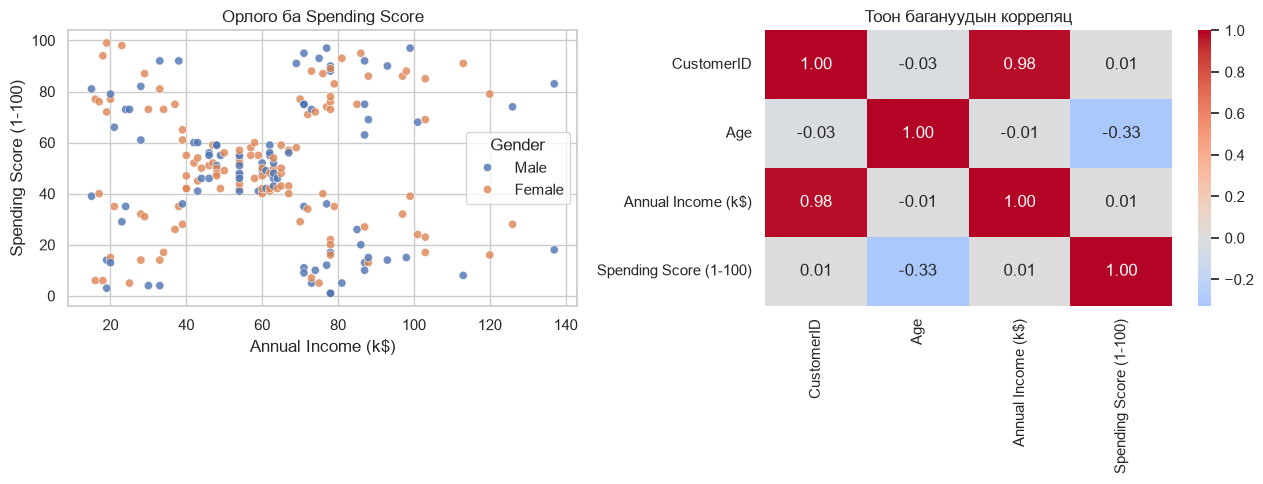

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Gender', alpha=.8, ax=axes[0])
axes[0].set_title('Орлого ба Spending Score')
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f', ax=axes[1])
axes[1].set_title('Тоон багануудын корреляц')
plt.tight_layout()
plt.show()

**EDA ажиглалт.** Орлого ба Spending Score-ийн scatter plot дээр хэрэглэгчид хэд хэдэн бүлэг болон харагдаж байгаа нь сегментчлэлд ашиглах боломжтойг харуулна. Насны тархалт болон Spending Score-ийн boxplot нь тархалтын хэлбэр, боломжит хэт утгыг шалгана. Корреляцийн хүснэгтээс CustomerID зэрэг таних дугаарын хамаарлыг зан төлөв гэж тайлбарлахгүй; загварт зөвхөн орлого ба оноог сонгов.

## 3. Feature сонголт ба scaling
`Annual Income (k$)` болон `Spending Score (1-100)`-г сонгов. Хэмжээс ялгаатай тул StandardScaler хэрэглэж, эх `df`-г өөрчлөхгүй хадгална.

In [17]:
FEATURES = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Scaled дундаж:', X_scaled.mean(axis=0).round(3))
print('Scaled стандарт хазайлт:', X_scaled.std(axis=0).round(3))

Scaled дундаж: [-0. -0.]
Scaled стандарт хазайлт: [1. 1.]


## 4. Elbow арга — K сонгох
K=1–10 утгад KMeans fit хийж inertia буюу кластер доторх квадрат алдааны нийлбэрийг харьцуулна.

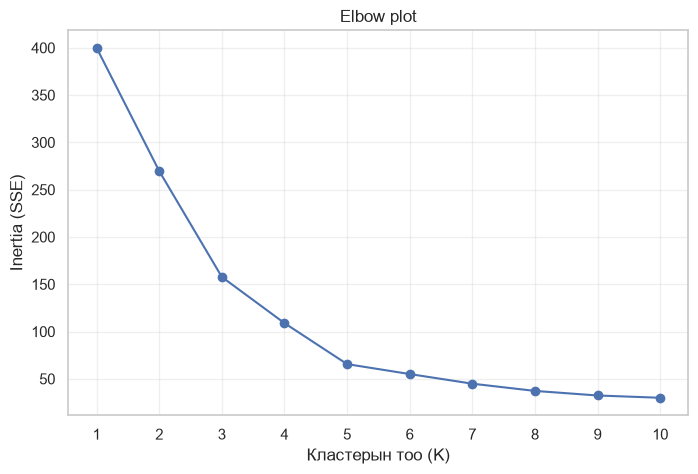

In [18]:
k_values = range(1, 11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker='o')
plt.xticks(list(k_values))
plt.xlabel('Кластерын тоо (K)')
plt.ylabel('Inertia (SSE)')
plt.title('Elbow plot')
plt.grid(True, alpha=.3)
plt.show()

**K сонголт.** Энэ өгөгдлийн орлого–Spending Score тархалтад муруйн огцом бууралт K=5 орчимд саарч, цааш inertia-ийн сайжрал багасдаг тул K=5-г сонгов. Elbow нь графикийн нүдэн үнэлгээ тул үр дүнг профайл болон scatter plot-той хамт тайлбарлана.

## 5. KMeans загвар ба кластерууд
Сонгосон K=5 утгаар дахин сургаж, шошго ба төвүүдийг анхны нэгж рүү хөрвүүлнэ.

In [19]:
SELECTED_K = 5
kmeans = KMeans(n_clusters=SELECTED_K, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
clustered = df.copy()
clustered['Cluster'] = labels
centers_original = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)
centers_original.index.name = 'Cluster'
print('Кластерын төвүүд (анхны хэмжээсээр):')
display(centers_original.round(2))
print('Кластер тус бүрийн хэрэглэгчийн тоо:')
display(clustered['Cluster'].value_counts().sort_index().rename('Customers').to_frame())

Кластерын төвүүд (анхны хэмжээсээр):


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


Кластер тус бүрийн хэрэглэгчийн тоо:


,Customers
Cluster,
0,81
1,39
2,22
3,35
4,23


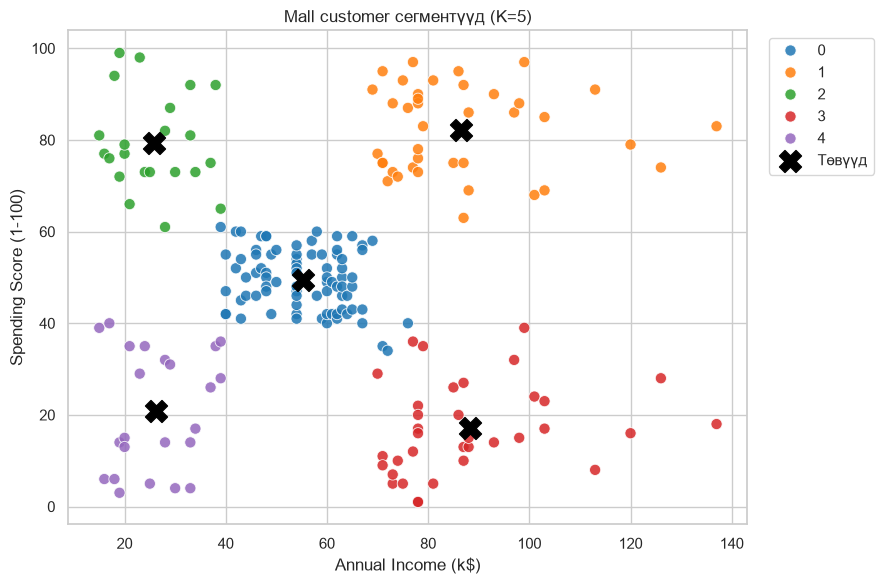

In [20]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=clustered, x=FEATURES[0], y=FEATURES[1], hue='Cluster', palette='tab10', s=65, alpha=.85)
plt.scatter(centers_original[FEATURES[0]], centers_original[FEATURES[1]], marker='X', s=250, c='black', label='Төвүүд')
plt.title(f'Mall customer сегментүүд (K={SELECTED_K})')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Кластерын профиль ба тайлбар
Дундаж нас, жилийн орлого, Spending Score болон кластерын хэмжээг гаргана. Кластерын дугаар дурын шошго тул нэршлийг хэмжсэн дундажид үндэслэн онооно.

In [25]:
profile = clustered.groupby('Cluster').agg(
    Customers=('CustomerID', 'size'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Annual Income (k$)', 'mean'),
    Mean_Spending_Score=('Spending Score (1-100)', 'mean'),
).round(1)
profile['Segment'] = [
    'дундаж орлого – дундаж хэрэглээ',
    'Өндөр орлого – өндөр хэрэглээ',
    'Бага орлого – өндөр хэрэглээ',
    'Өндөр орлого – бага хэрэглээ',
    'Бага орлого – бага хэрэглээ',
]
display(profile)

,Customers,Mean_Age,Mean_Income,Mean_Spending_Score,Segment
Cluster,,,,,
0,81,42.7,55.3,49.5,дундаж орлого – дундаж хэрэглээ
1,39,32.7,86.5,82.1,Өндөр орлого – өндөр хэрэглээ
2,22,25.3,25.7,79.4,Бага орлого – өндөр хэрэглээ
3,35,41.1,88.2,17.1,Өндөр орлого – бага хэрэглээ
4,23,45.2,26.3,20.9,Бага орлого – бага хэрэглээ


## 7. Дүгнэлт
K-means нь жилийн орлого ба Spending Score-ийн дагуу хэрэглэгчдийг таван сегментэд бүлэглэв. Орлого өндөр байх нь дангаараа өндөр Spending Score гэсэн үг биш: өндөр орлоготой боловч зарцуулалтын оноо бага бүлэг ч илэрч болно. Ийм профайлууд нь урамшуулал, үйлчилгээг сегмент тус бүрт тохируулахад ашигтай. Үр дүн нь сонгосон feature, scaling арга болон K=5 сонголтоос хамаарах тул профайлыг бодит хэрэглээний нөхцөлтэй хамт үнэлнэ.